Mounted at /content/drive
Dataset loaded. Users: ['debora' 'katia' 'wallace' 'jose_carlos']

--- Phase 1: Nested LOSO CV (Performance Estimation) ---
Estimated Generalization F1-score: 0.8447

--- Phase 2: SHAP Explanation (Generalization Test) ---
Training on all users except: debora
Generating SHAP explanations for unseen user: debora

Visualizing Global Importance for unseen user: debora


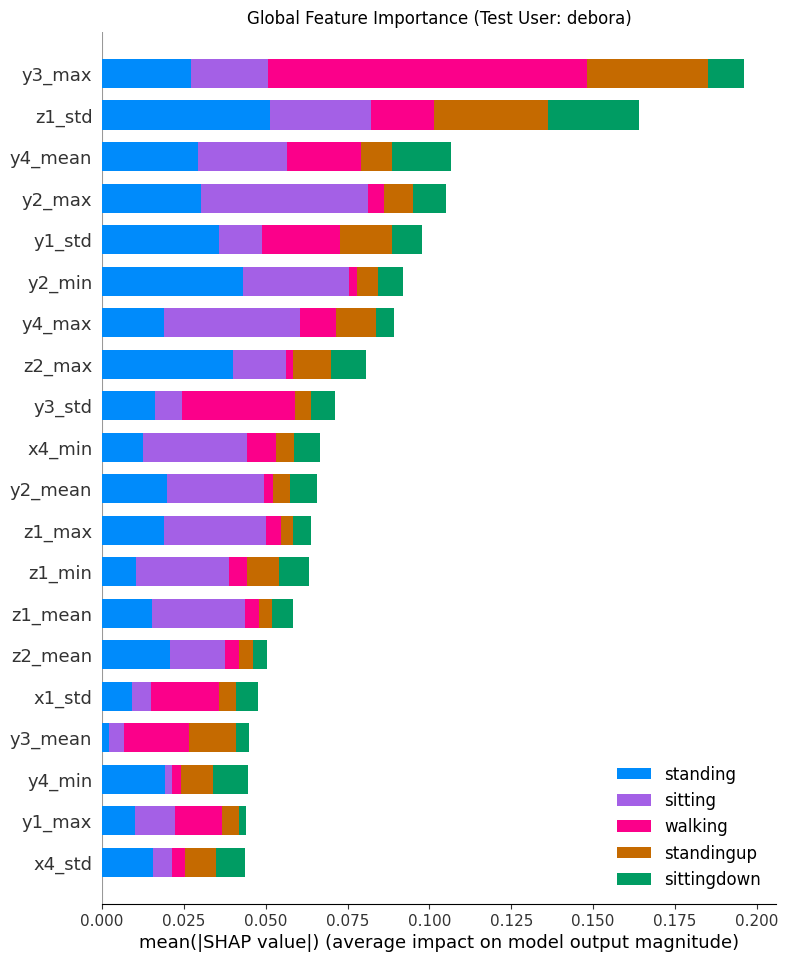


Visualizing Summary Plot for Class: sitting


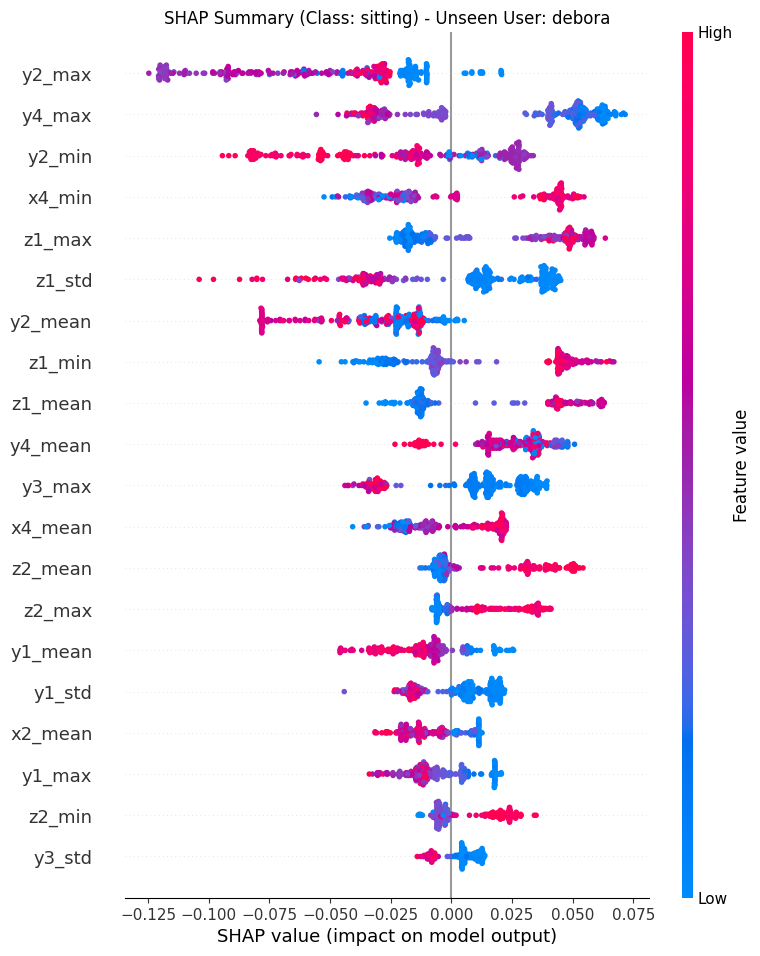


Visualizing Local Waterfall Plot for the first sample of debora


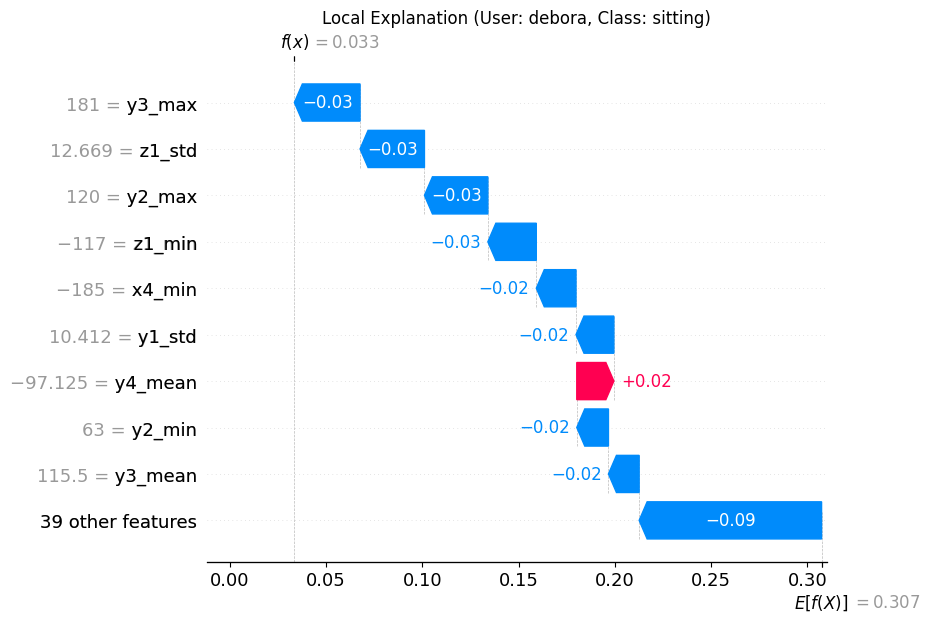

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, LeaveOneGroupOut, cross_val_score

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Load Dataset
dataset_path = '/content/drive/MyDrive/Colab/windowed.csv'
df = pd.read_csv(dataset_path)

if 'class' in df.columns and 'user' in df.columns:
    X = df.drop(columns=['class', 'user'])
    y = df['class']
    groups = df['user']
    unique_users = df['user'].unique()
    class_names = [str(c) for c in np.unique(y)]
    print(f"Dataset loaded. Users: {unique_users}")
else:
    raise ValueError("Columns 'class' or 'user' not found in dataset.")

# 3. Performance Estimation (Nested LOSO CV)
# This part estimates how well the model generalizes across all users
print("\n--- Phase 1: Nested LOSO CV (Performance Estimation) ---")
rf_classifier = RandomForestClassifier(random_state=42, n_jobs=-1)
param_dist = {
    'n_estimators': [100, 150],
    'max_depth': [10, 20, None],
    'max_features': ['sqrt']
}

inner_search = RandomizedSearchCV(
    estimator=rf_classifier,
    param_distributions=param_dist,
    n_iter=3,
    cv=2,
    scoring='f1_weighted',
    random_state=42
)

loso = LeaveOneGroupOut()
nested_scores = cross_val_score(
    inner_search, X, y, groups=groups, cv=loso, scoring='f1_weighted', n_jobs=-1
)
print(f"Estimated Generalization F1-score: {np.mean(nested_scores):.4f}")

# 4. SHAP Analysis on a Held-out User
# To explain "Generalization", we train on N-1 users and test SHAP on the Nth user
print("\n--- Phase 2: SHAP Explanation (Generalization Test) ---")

# We pick one user to be the 'unseen' test subject (e.g., the first user in the list)
test_user = unique_users[0]
train_idx = df['user'] != test_user
test_idx = df['user'] == test_user

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

print(f"Training on all users except: {test_user}")
print(f"Generating SHAP explanations for unseen user: {test_user}")

# Fit the model on training users only
best_inner_model = inner_search.fit(X_train, y_train)
final_model = best_inner_model.best_estimator_

# 5. SHAP Calculation
explainer = shap.TreeExplainer(final_model)

# Sample from the TEST SET (unseen user) for speed
shap_sample_size = min(300, X_test.shape[0])
X_shap_test_sample = X_test.sample(shap_sample_size, random_state=42)
shap_values = explainer.shap_values(X_shap_test_sample)

# Handle SHAP output format (list for multi-class)
is_list = isinstance(shap_values, list)

# --- VISUALIZATION 1: Global Importance for Unseen User ---
print(f"\nVisualizing Global Importance for unseen user: {test_user}")
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_shap_test_sample, plot_type="bar", class_names=class_names, show=False)
plt.title(f"Global Feature Importance (Test User: {test_user})")
plt.show()

# --- VISUALIZATION 2: Summary Plot for a specific class ---
# Let's visualize the first class in the dataset
target_class_index = 0
print(f"\nVisualizing Summary Plot for Class: {class_names[target_class_index]}")
plt.figure(figsize=(10, 6))
vals = shap_values[target_class_index] if is_list else shap_values[:, :, target_class_index]
shap.summary_plot(vals, X_shap_test_sample, show=False)
plt.title(f"SHAP Summary (Class: {class_names[target_class_index]}) - Unseen User: {test_user}")
plt.show()

# --- VISUALIZATION 3: Local Waterfall Plot ---
# Explain the first prediction of the unseen user
print(f"\nVisualizing Local Waterfall Plot for the first sample of {test_user}")
sample_idx = 0
if is_list:
    current_shap_vals = shap_values[target_class_index][sample_idx]
    base_val = explainer.expected_value[target_class_index]
else:
    current_shap_vals = shap_values[sample_idx, :, target_class_index]
    base_val = explainer.expected_value[target_class_index]

exp = shap.Explanation(
    values=current_shap_vals,
    base_values=base_val,
    data=X_shap_test_sample.iloc[sample_idx].values,
    feature_names=X.columns.tolist()
)

plt.figure()
shap.plots.waterfall(exp, show=False)
plt.title(f"Local Explanation (User: {test_user}, Class: {class_names[target_class_index]})")
plt.show()